In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import sqlite3

#sqlite3 is a built-in Python library.
#It allows Python to connect to and work with SQLite databases.
#We can create, read, update and delete database records.

In [135]:
con = sqlite3.connect(r'E:\Tharindu\New folder\Udemy\DS Real World Projects in Python\Project 02 - Password Resources\password_resources\password_data.sqlite')

#sqlite3.connect() connects Python to a database.
#con stores the database connection.

In [136]:
data = pd.read_sql_query("SELECT * FROM Users", con)

#read_sql_query() - Executes an SQL query and returns the result as a DataFrame

In [7]:
data.shape

(100000, 3)

In [8]:
data.head(4)

,index,password,strength
0,0,zxe870819,1
1,1,xw46454nr23l,1
2,2,soporte13,1
3,3,accounts6000webhost.com,2


In [9]:
data.columns

Index(['index', 'password', 'strength'], dtype='object')

## Drop irrelevant columns

In [10]:
data.drop(["index"], axis=1, inplace=True)

In [11]:
data.head(4)

,password,strength
0,zxe870819,1
1,xw46454nr23l,1
2,soporte13,1
3,accounts6000webhost.com,2


## See duplicated values

In [12]:
data.duplicated().sum()

np.int64(0)

## See missing values

In [13]:
data.isnull().any()

password    False
strength    False
dtype: bool

In [14]:
data.isnull().any().sum()

np.int64(0)

In [15]:
data.dtypes

password    object
strength     int64
dtype: object

## Check it has irrelevant rows like -1

In [16]:
data['strength']

0        1
1        1
2        1
3        2
4        1
        ..
99995    1
99996    1
99997    1
99998    1
99999    1
Name: strength, Length: 100000, dtype: int64

In [17]:
data['strength'].unique()

array([1, 2, 0])

## Performing Semantic Analysis

##### Semantic Analysis = Understanding the meaning of text.

In [18]:
data.columns

Index(['password', 'strength'], dtype='object')

In [19]:
data["password"]

0                      zxe870819
1                   xw46454nr23l
2                      soporte13
3        accounts6000webhost.com
4                       c443balg
                  ...           
99995                 obejofi215
99996                 fmiopvxb64
99997                  czvrbun38
99998                  mymyxe430
99999                glqjhkxb467
Name: password, Length: 100000, dtype: object

In [20]:
data["password"][0]

'zxe870819'

In [21]:
type(data["password"][0])

str

## passwordv actually holds only numeric characters

In [22]:
data["password"].str.isnumeric()

0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: password, Length: 100000, dtype: bool

In [23]:
data[data["password"].str.isnumeric()]

,password,strength
12280,943801,0
14992,12345,0
20958,147856,0
21671,140290,0
23269,123987,0
28569,1233214,0
31329,0159456,0
32574,363761,0
37855,4524344,0
43648,5521597,0


In [24]:
data[data["password"].str.isnumeric()].shape

(26, 2)

## password, actually holds only Upper-case character 

In [25]:
data["password"].str.isupper()

0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: password, Length: 100000, dtype: bool

In [26]:
data[data["password"].str.isupper()]

,password,strength
115,EYT63119,1
273,INSPIRON6,1
338,1A2S3D4F,1
367,13269123A,1
373,YAMAZAKI82,1
...,...,...
99590,V13000993J,1
99692,65925013ABC,1
99784,01EDD055,1
99893,1UPONYOU,1


In [27]:
data[data["password"].str.isupper()].shape

(1506, 2)

## password, actually holds only alphabet

In [28]:
data["password"].str.isalpha()

0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: password, Length: 100000, dtype: bool

In [29]:
data[data["password"].str.isalpha()]

,password,strength
267,PomarancaÇ,1
1380,smgodt,0
3198,cuado,0
4560,jelsz,0
6380,demsxp,0
7803,secret,0
9218,caballo,0
11555,mhe,0
11667,kreedo,0
13645,nõmlich,0


In [30]:
data[data["password"].str.isalpha()].shape

(50, 2)

## password, actually holds alpha-numeric character 

In [31]:
data["password"].str.isalnum()

0         True
1         True
2         True
3        False
4         True
         ...  
99995     True
99996     True
99997     True
99998     True
99999     True
Name: password, Length: 100000, dtype: bool

In [32]:
data[data["password"].str.isalnum()]

,password,strength
0,zxe870819,1
1,xw46454nr23l,1
2,soporte13,1
4,c443balg,1
5,16623670p,1
...,...,...
99995,obejofi215,1
99996,fmiopvxb64,1
99997,czvrbun38,1
99998,mymyxe430,1


In [33]:
data[data["password"].str.isalnum()].shape

(97203, 2)

## password, actually holds title-case character

In [34]:
data["password"].str.istitle()

0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: password, Length: 100000, dtype: bool

In [35]:
data[data["password"].str.istitle()]

,password,strength
64,Hisanthoshjasika0,2
242,Therockrockbottom72,2
338,1A2S3D4F,1
367,13269123A,1
526,Csicskarozsika1,2
...,...,...
99168,1053815198M,1
99192,Alfranx05122023,2
99375,Kensington1956,2
99590,V13000993J,1


In [36]:
data[data["password"].str.istitle()].shape

(932, 2)

## password, actually holds special character 

In [37]:
data["password"]

0                      zxe870819
1                   xw46454nr23l
2                      soporte13
3        accounts6000webhost.com
4                       c443balg
                  ...           
99995                 obejofi215
99996                 fmiopvxb64
99997                  czvrbun38
99998                  mymyxe430
99999                glqjhkxb467
Name: password, Length: 100000, dtype: object

In [38]:
import string

In [39]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [40]:
def find_semantics(row):
    for char in row:
        if char in string.punctuation:
            return 1
        else:
            pass

In [41]:
data["password"].apply(find_semantics)

0        NaN
1        NaN
2        NaN
3        1.0
4        NaN
        ... 
99995    NaN
99996    NaN
99997    NaN
99998    NaN
99999    NaN
Name: password, Length: 100000, dtype: float64

In [42]:
data["password"].apply(find_semantics) == 1

0        False
1        False
2        False
3         True
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: password, Length: 100000, dtype: bool

In [43]:
data[data["password"].apply(find_semantics) == 1]

,password,strength
3,accounts6000webhost.com,2
68,12463773800+,1
98,p.r.c.d.g.,1
145,cita-cita,1
180,karolina.susnina0U,2
...,...,...
99748,maiselis.com,1
99845,hosting4meze!@#,2
99954,semista_bakung15,2
99980,halflife2010!LEB,2


In [44]:
data[data["password"].apply(find_semantics) == 1].shape

(2663, 2)

## Applying Feature Engineering

In [45]:
data["password"]

0                      zxe870819
1                   xw46454nr23l
2                      soporte13
3        accounts6000webhost.com
4                       c443balg
                  ...           
99995                 obejofi215
99996                 fmiopvxb64
99997                  czvrbun38
99998                  mymyxe430
99999                glqjhkxb467
Name: password, Length: 100000, dtype: object

In [138]:
data["password"][0]

'zxe870819'

In [47]:
len(data["password"][0])

9

In [141]:
data["length"] = data["password"].str.len()

In [142]:
data.head()

,index,password,strength,length
0,0,zxe870819,1,9
1,1,xw46454nr23l,1,12
2,2,soporte13,1,9
3,3,accounts6000webhost.com,2,23
4,4,c443balg,1,8


### Frequency of Lowercase Characters

In [50]:
password = "Tharindu123"

In [51]:
[char for char in password if char.islower()]

['h', 'a', 'r', 'i', 'n', 'd', 'u']

In [52]:
len([char for char in password if char.islower()])

7

In [53]:
len([char for char in password if char.islower()])/len(password)

0.6363636363636364

#### Frequency of Lowercase Characters :

In [54]:
def freq_lowercase(row):
    return len([char for char in row if char.islower()])/len(row)

#### Frequency of Uppercase Characters :

In [55]:
def freq_uppercase(row):
    return len([char for char in row if char.isupper()])/len(row)

#### Frequency of Numeric Characters :

In [56]:
def freq_numerical_case(row):
    return len([char for char in row if char.isdigit()])/len(row)

### Apply defind function

In [144]:
data["lowercase_freq"] = np.round(data["password"].apply(freq_lowercase), 3)

data["uppercase_freq"] = np.round(data["password"].apply(freq_uppercase), 3)

data["digit_freq"] = np.round(data["password"].apply(freq_numerical_case), 3)

In [147]:
data.head()

,index,password,strength,length,lowercase_freq,uppercase_freq,digit_freq
0,0,zxe870819,1,9,0.333,0.0,0.667
1,1,xw46454nr23l,1,12,0.417,0.0,0.583
2,2,soporte13,1,9,0.778,0.0,0.222
3,3,accounts6000webhost.com,2,23,0.783,0.0,0.174
4,4,c443balg,1,8,0.625,0.0,0.375


### Frequency of Special-Case Characters:

In [59]:
def freq_special_case(row):
    special_chars = []
    for char in row:
        if not char.isalpha() and not char.isdigit():
            special_chars.append(char)
    return len(special_chars)        

In [60]:
data["special_char_freq"] = np.round(data["password"].apply(freq_special_case), 3)

In [61]:
data.head(5)

,password,strength,length,lowercase_freq,uppercase_freq,digit_freq,special_char_freq
0,zxe870819,1,9,0.333,0.0,0.667,0
1,xw46454nr23l,1,12,0.417,0.0,0.583,0
2,soporte13,1,9,0.778,0.0,0.222,0
3,accounts6000webhost.com,2,23,0.783,0.0,0.174,1
4,c443balg,1,8,0.625,0.0,0.375,0


In [62]:
data["special_char_freq"] = data["special_char_freq"]/data["length"]

In [63]:
data.head()

,password,strength,length,lowercase_freq,uppercase_freq,digit_freq,special_char_freq
0,zxe870819,1,9,0.333,0.0,0.667,0.000000
1,xw46454nr23l,1,12,0.417,0.0,0.583,0.000000
2,soporte13,1,9,0.778,0.0,0.222,0.000000
3,accounts6000webhost.com,2,23,0.783,0.0,0.174,0.043478
4,c443balg,1,8,0.625,0.0,0.375,0.000000


## Performing Descriptive Statistics

In [64]:
data.columns

Index(['password', 'strength', 'length', 'lowercase_freq', 'uppercase_freq',
       'digit_freq', 'special_char_freq'],
      dtype='object')

In [65]:
data[["length", "strength"]]

,length,strength
0,9,1
1,12,1
2,9,1
3,23,2
4,8,1
...,...,...
99995,10,1
99996,10,1
99997,9,1
99998,9,1


In [66]:
data[["length", "strength"]].groupby(["strength"]).agg(["min", "max", "mean", "median"])

length                       
            min  max       mean median
strength                              
0             1    7   6.550947    7.0
1             8   13   9.611074    9.0
2            14  220  15.953421   16.0

In [67]:
data.columns

Index(['password', 'strength', 'length', 'lowercase_freq', 'uppercase_freq',
       'digit_freq', 'special_char_freq'],
      dtype='object')

In [68]:
cols = ["length", "lowercase_freq", "uppercase_freq", "digit_freq", "special_char_freq"]

for col in cols:
    print(col)
    print(data[[col, "strength"]].groupby(["strength"]).agg(["min", "max", "mean", "median"]))
    print("\n")

length
         length                       
            min  max       mean median
strength                              
0             1    7   6.550947    7.0
1             8   13   9.611074    9.0
2            14  220  15.953421   16.0


lowercase_freq
         lowercase_freq                        
                    min    max      mean median
strength                                       
0                   0.0  1.000  0.708050  0.714
1                   0.0  0.923  0.630067  0.667
2                   0.0  0.917  0.424679  0.400


uppercase_freq
         uppercase_freq                        
                    min    max      mean median
strength                                       
0                   0.0  1.000  0.012872  0.000
1                   0.0  0.923  0.007915  0.000
2                   0.0  0.889  0.367633  0.429


digit_freq
         digit_freq                        
                min    max      mean median
strength                                   
0   

Weak passwords mainly consist of lowercase letters.

Medium passwords contain a higher proportion of digits.

Strong passwords tend to contain more uppercase letters and special characters.

Strong passwords generally have a more varied character composition.

In [69]:
data.columns

Index(['password', 'strength', 'length', 'lowercase_freq', 'uppercase_freq',
       'digit_freq', 'special_char_freq'],
      dtype='object')

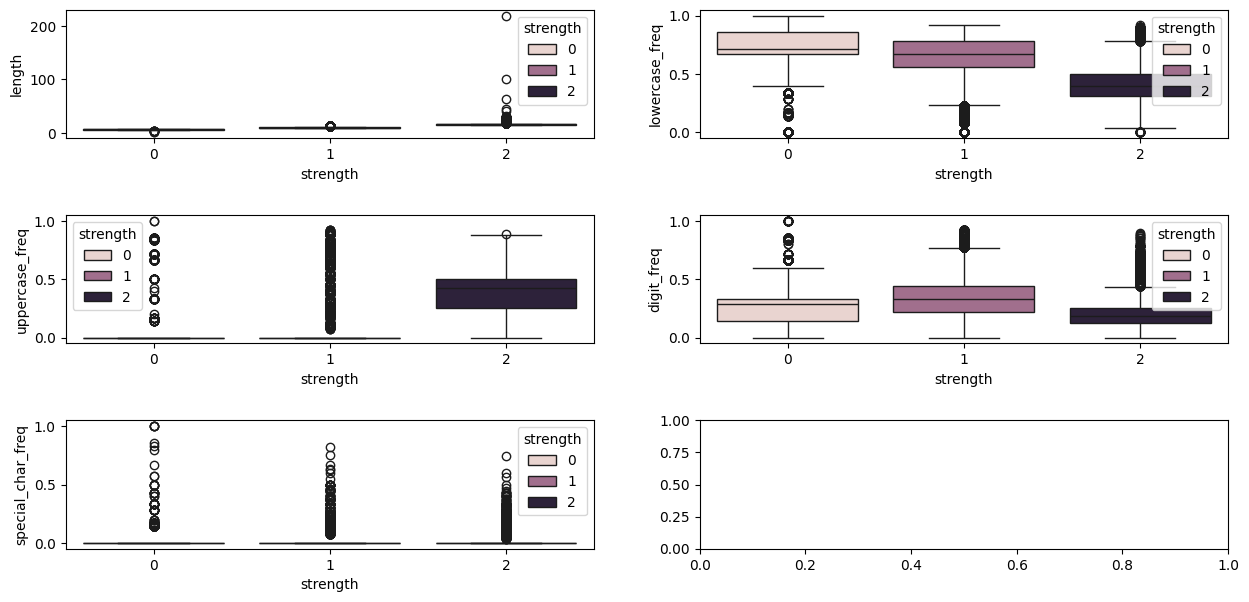

In [70]:
fig , ((ax1 , ax2) , (ax3 , ax4) , (ax5,ax6)) = plt.subplots(3 , 2 , figsize=(15,7))

sns.boxplot(x="strength" , y='length' , hue="strength" , ax=ax1 , data=data)
sns.boxplot(x="strength" , y='lowercase_freq' , hue="strength" , ax=ax2, data=data)
sns.boxplot(x="strength" , y='uppercase_freq' , hue="strength" , ax=ax3, data=data)
sns.boxplot(x="strength" , y='digit_freq' , hue="strength" , ax=ax4, data=data)
sns.boxplot(x="strength" , y='special_char_freq' , hue="strength" , ax=ax5, data=data)

plt.subplots_adjust(hspace=0.6)

## Feature Importance

In [71]:
data.columns

Index(['password', 'strength', 'length', 'lowercase_freq', 'uppercase_freq',
       'digit_freq', 'special_char_freq'],
      dtype='object')

In [72]:
def get_dist(data, feature):

    plt.figure(figsize=(10, 8))
    plt.subplot(1, 2, 1)

    sns.violinplot(x="strength", y=feature, data=data)

    plt.subplot(1, 2, 2)

    sns.distplot(data[data['strength']==0][feature] , color="red" , label="0" , hist=False)
    sns.distplot(data[data['strength']==1][feature], color="blue", label="1", hist=False)
    sns.distplot(data[data['strength']==2][feature], color="orange", label="2", hist=False)
    plt.legend()
    plt.show()

In [73]:
import warnings
from warnings import filterwarnings
filterwarnings("ignore")

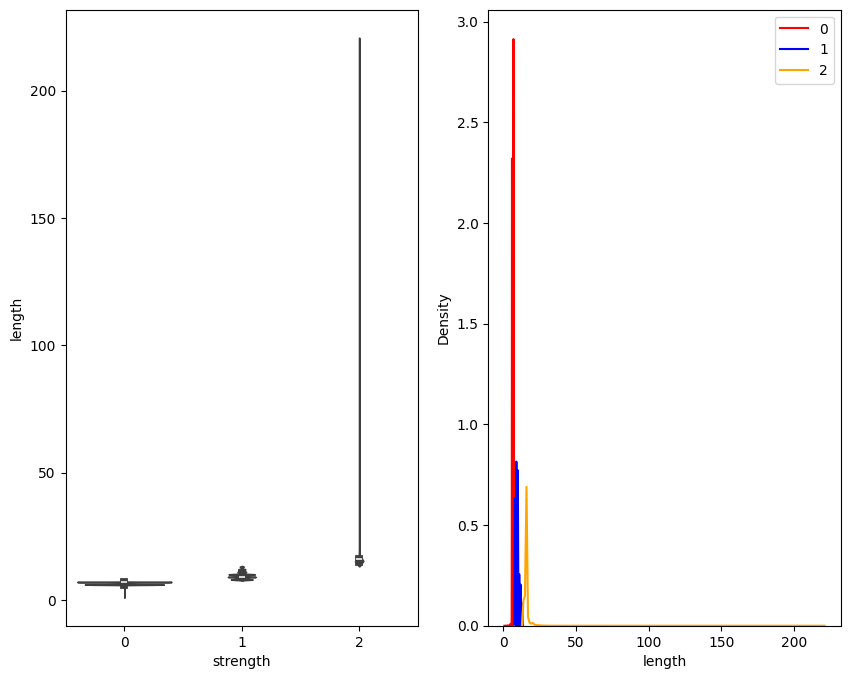

In [74]:
get_dist(data, "length")

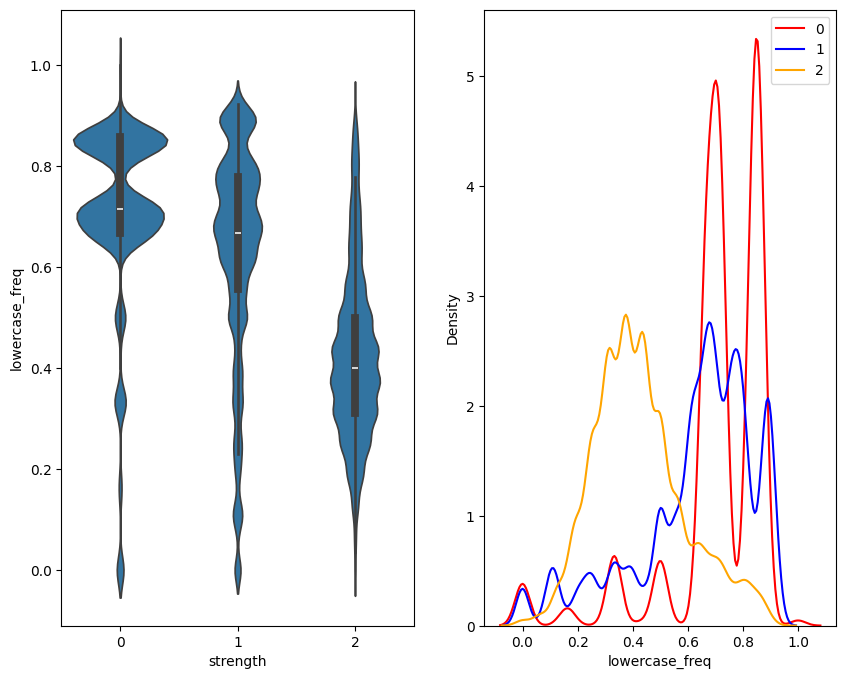

In [75]:
get_dist(data , 'lowercase_freq')

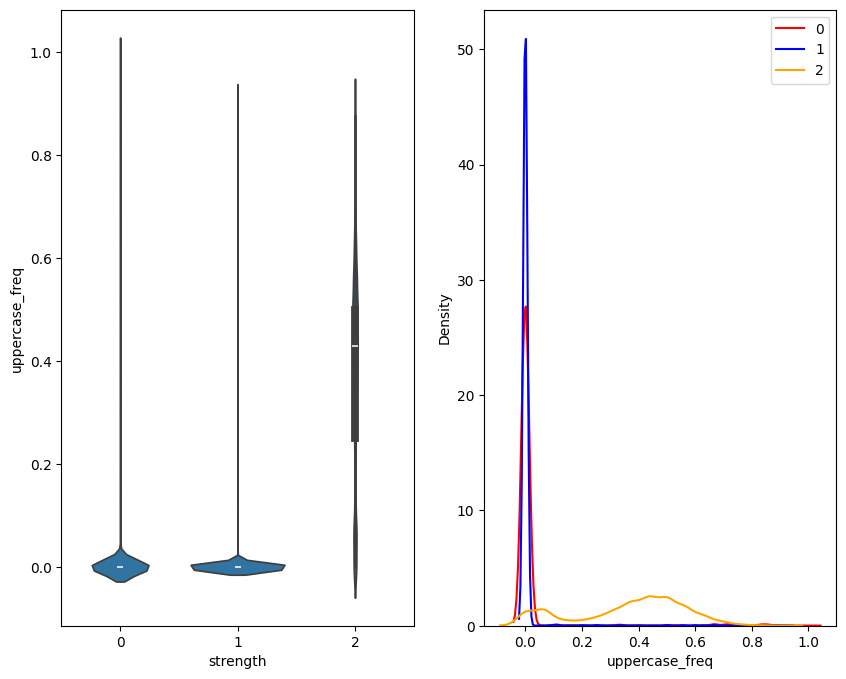

In [76]:
get_dist(data , 'uppercase_freq')

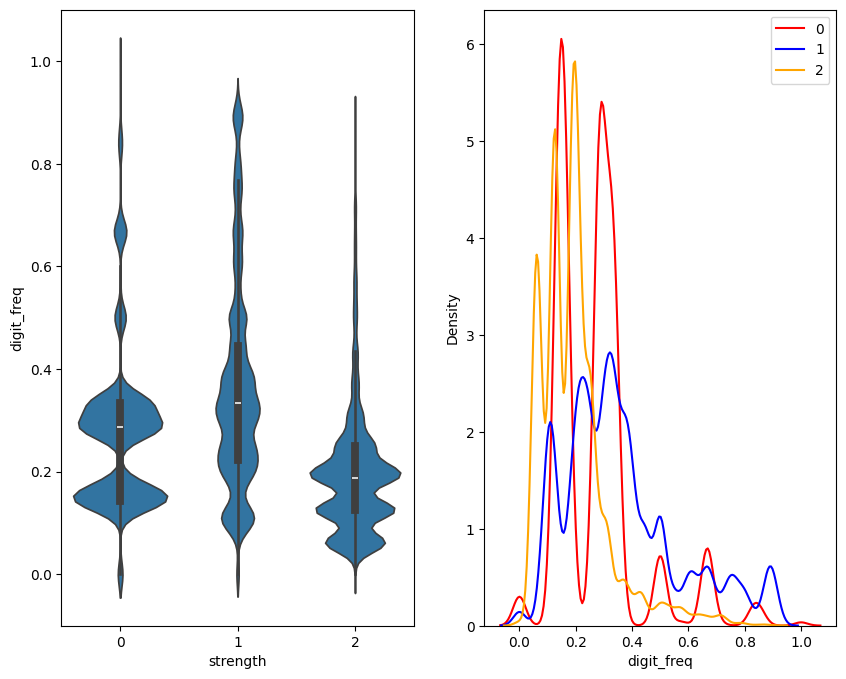

In [77]:
get_dist(data , 'digit_freq')

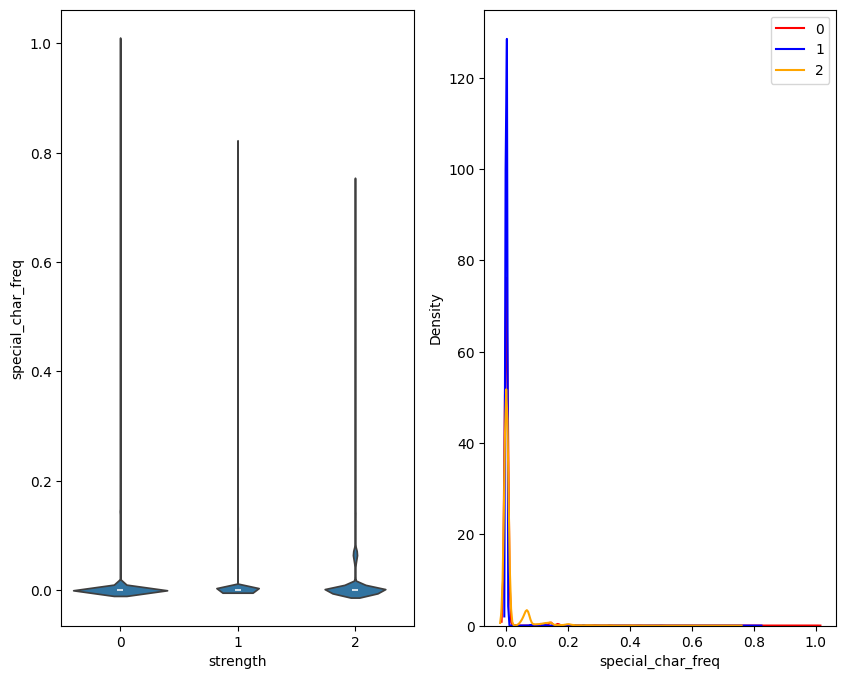

In [78]:
get_dist(data , 'special_char_freq')

## Applying TF_IDF on data

TF = How frequently a word appears in a document.

IDF = How rare a word is across all documents.

TF-IDF = Importance of a word in a document.

In [79]:
data

,password,strength,length,lowercase_freq,uppercase_freq,digit_freq,special_char_freq
0,zxe870819,1,9,0.333,0.0,0.667,0.000000
1,xw46454nr23l,1,12,0.417,0.0,0.583,0.000000
2,soporte13,1,9,0.778,0.0,0.222,0.000000
3,accounts6000webhost.com,2,23,0.783,0.0,0.174,0.043478
4,c443balg,1,8,0.625,0.0,0.375,0.000000
...,...,...,...,...,...,...,...
99995,obejofi215,1,10,0.700,0.0,0.300,0.000000
99996,fmiopvxb64,1,10,0.800,0.0,0.200,0.000000
99997,czvrbun38,1,9,0.778,0.0,0.222,0.000000
99998,mymyxe430,1,9,0.667,0.0,0.333,0.000000


In [80]:
dataframe = data.sample(frac=1) #shuffles all rows of a DataFrame randomly

In [81]:
dataframe

,password,strength,length,lowercase_freq,uppercase_freq,digit_freq,special_char_freq
43480,kimo2010,1,8,0.500,0.000,0.500,0.000000
64254,soyjulio1,1,9,0.889,0.000,0.111,0.000000
34919,kiladado123,1,11,0.727,0.000,0.273,0.000000
56556,uDpYVETgwOAKRjr7,2,16,0.375,0.562,0.062,0.000000
47471,zanda20,0,7,0.714,0.000,0.286,0.000000
...,...,...,...,...,...,...,...
35658,viqywa583,1,9,0.667,0.000,0.333,0.000000
16788,zpy4023993,1,10,0.300,0.000,0.700,0.000000
67908,ban211369,1,9,0.333,0.000,0.667,0.000000
65252,cifiw555,1,8,0.625,0.000,0.375,0.000000


In [82]:
x = list(dataframe["password"])

In [83]:
#x

In [84]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [148]:
vectorizer = TfidfVectorizer(
    analyzer="char",
    lowercase=False
)

In [149]:
X = vectorizer.fit_transform(x)

In [150]:
X.shape

(100000, 126)

In [151]:
dataframe["password"].shape

(100000,)

In [152]:
X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 855304 stored elements and shape (100000, 126)>

In [153]:
X.toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(100000, 126))

In [154]:
X.toarray()[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.64107955, 0.24591225, 0.28450855, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [155]:
dataframe["password"]

43480            kimo2010
64254           soyjulio1
34919         kiladado123
56556    uDpYVETgwOAKRjr7
47471             zanda20
               ...       
35658           viqywa583
16788          zpy4023993
67908           ban211369
65252            cifiw555
67809           kishore@c
Name: password, Length: 100000, dtype: object

In [156]:
vectorizer.get_feature_names_out()

array(['\x04', '\x06', '\x08', '\x0e', '\x10', '\x11', '\x17', ' ', '!',
       '#', '$', '%', '&', '(', ')', '*', '+', '-', '.', '/', '0', '1',
       '2', '3', '4', '5', '6', '7', '8', '9', ';', '<', '=', '>', '?',
       '@', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L',
       'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y',
       'Z', '[', '\\', ']', '^', '_', '`', 'a', 'b', 'c', 'd', 'e', 'f',
       'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's',
       't', 'u', 'v', 'w', 'x', 'y', 'z', '{', '|', '}', '~', '¡', '¨',
       '°', '±', '³', '´', 'µ', '·', 'Ä', 'Ç', 'É', 'Í', 'Ó', 'Ö', 'Ú',
       'Ü', 'Ý', 'ß', 'à', 'á', 'æ', 'ê', 'í', 'ñ', 'õ', '÷', 'þ', '›'],
      dtype=object)

In [157]:
len(vectorizer.get_feature_names_out())

126

In [158]:
df2 = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

In [159]:
df2

,,,,,,,,,!,#,...,à,á,æ,ê,í,ñ,õ,÷,þ,›
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99996,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
99998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Applying Machine Learning Algorithm

In [160]:
dataframe.columns

Index(['password', 'strength', 'length', 'lowercase_freq', 'uppercase_freq',
       'digit_freq', 'special_char_freq'],
      dtype='object')

In [161]:
df2["length"] = dataframe['length']
df2["lowercase_freq"] = dataframe['lowercase_freq']

In [162]:
df2

,,,,,,,,,!,#,...,æ,ê,í,ñ,õ,÷,þ,›,length,lowercase_freq
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9,0.333
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12,0.417
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9,0.778
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,23,0.783
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8,0.625
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10,0.700
99996,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10,0.800
99997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9,0.778
99998,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9,0.667


In [163]:
y = dataframe["strength"]

In [164]:
from sklearn.model_selection import train_test_split

In [165]:
X_train, X_test, y_train, y_test = train_test_split(df2, y, test_size=0.20)


In [166]:
X_train.shape

(80000, 128)

In [167]:
y_train.shape

(80000,)

In [168]:
from sklearn.linear_model import LogisticRegression

In [169]:
clf = LogisticRegression(multi_class="multinomial")

In [170]:
clf.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'multinomial'


In [171]:
y_pred = clf.predict(X_test)

In [172]:
y_pred

array([1, 1, 1, ..., 0, 1, 1], shape=(20000,))

In [173]:
from collections import Counter

In [174]:
Counter(y_pred)

Counter({np.int64(1): 16528, np.int64(2): 2317, np.int64(0): 1155})

## Doing Prediction on Sample Data (User Input)

In [175]:
password = "Tharindu@123"

In [176]:
sample_array = np.array([password])

In [177]:
sample_matrix = vectorizer.transform(sample_array)

In [178]:
sample_matrix.toarray()

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.17059759, 0.19737314, 0.22105878, 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.57967371, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.40986605, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.17316886, 0.        ,
        0.        , 0.26390857, 0.        , 0.  

In [179]:
sample_matrix.toarray().shape

(1, 126)

In [180]:
password

'Tharindu@123'

In [181]:
len(password)

12

In [182]:
[char for char in password if char.islower()]

['h', 'a', 'r', 'i', 'n', 'd', 'u']

In [183]:
len([char for char in password if char.islower()])

7

In [184]:
len([char for char in password if char.islower()])/len(password)

0.5833333333333334

In [186]:
np.append(sample_matrix.toarray(), (12, 0.5833333333333334)).reshape(1, 128)

array([[ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.17059759,  0.19737314,  0.22105878,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.57967371,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.40986605,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.1

In [188]:
np.append(sample_matrix.toarray(), (12, 0.5833333333333334)).reshape(1, 128).shape

(1, 128)

In [189]:
new_matrix = np.append(sample_matrix.toarray(), (12, 0.5833333333333334)).reshape(1, 128)

In [190]:
clf.predict(new_matrix)

array([2])

In [193]:
def predict():
    password = input("Enter a password : ")
    sample_array = np.array([password])
    sample_matrix = vectorizer.transform(sample_array)
    
    length_pass = len(password)
    length_normalised_lowercase = len([char for char in password if char.islower()])/len(password)
    
    new_matrix2 = np.append(sample_matrix.toarray() , (length_pass , length_normalised_lowercase)).reshape(1,128)
    result = clf.predict(new_matrix2)
    
    if result == 0 :
        return "Password is weak"
    elif result == 1 :
        return "Password is normal"
    else:
        return "password is strong"

In [195]:
predict()

Enter a password :  2334


'Password is normal'

In [128]:
predict()

Enter a password :  123


'Password is normal'

In [129]:
predict()

Enter a password :  123


'Password is normal'

In [130]:
predict()

Enter a password :  1233


'Password is normal'

## Model Evaluation

In [196]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [197]:
accuracy_score(y_test, y_pred)

0.83665

In [198]:
confusion_matrix(y_test, y_pred)

array([[  650,  2063,    39],
       [  480, 14026,   221],
       [   25,   439,  2057]])

In [199]:
print(classification_report(y_test , y_pred))

              precision    recall  f1-score   support

           0       0.56      0.24      0.33      2752
           1       0.85      0.95      0.90     14727
           2       0.89      0.82      0.85      2521

    accuracy                           0.84     20000
   macro avg       0.77      0.67      0.69     20000
weighted avg       0.81      0.84      0.81     20000



In [200]:
import joblib

# Save the trained model
joblib.dump(clf, "password_model.pkl")

# Save the TF-IDF vectorizer
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("Model and Vectorizer saved successfully!")

Model and Vectorizer saved successfully!
